# Volume holographic gratings: Kogelnik's coupled waves

The surface relief gratings of
notebook 123 (AR waveguide combiners) are thin:
their grooves are a fraction of a wavelength deep, and they diffract
light of any colour and any angle into the same set of orders. A **volume
holographic grating** (VHG) is the opposite: a weak sinusoidal modulation
of the refractive index, recorded by two interfering laser beams in a
photopolymer layer tens of wavelengths thick. Light diffracts strongly
only if it meets the fringes at the **Bragg angle**, where the waves
scattered by all fringes add in phase; a degree or a few nanometres off,
they cancel. Combiners from DigiLens, Sony and others, holographic
optical elements for head-up displays, wavelength-stabilizing gratings
of laser diodes and holographic data storage use this selectivity.

The standard theory is Herbert Kogelnik's coupled wave theory of 1969:
two waves (the incident one and one diffracted order) exchange power as
they travel through the grating. It has closed forms for transmission
and reflection gratings (`arvr.kogelnik()`), and we check it against
rigorous solutions: RCWA (`litho.rcwa`, the grating sliced by
`arvr.volume_grating()`) and the transfer matrices of `thin_films`
(notebook 12, layer stacks) for gratings whose fringes are
parallel to the surface. The sections are:

1. the Bragg condition and the two kinds of gratings,
2. transmission gratings: efficiency against modulation, angular
   selectivity, Kogelnik against RCWA, and when a grating is thick,
3. reflection gratings: the Bragg mirror inside the hologram, Kogelnik
   against thin films, and the spectral selectivity,
4. selectivity as a design parameter: the field of view of a VHG
   in-coupler, multiplexing, and why VHG combiners show no rainbow.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import arvr
from pyoptics import thin_films as tf
from pyoptics import sketch
from pyoptics.litho.rcwa import rcwa

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. The Bragg condition

The index of the grating is $n(\mathbf r) = n_0 + n_1\cos(\mathbf K\cdot\mathbf r)$,
with the grating vector $\mathbf K$ perpendicular to the fringes,
$|\mathbf K| = 2\pi/\Lambda$, at the angle $\phi$ to the surface normal
(the slant). The incident wave $R$ with the wave vector $\boldsymbol\rho$
($|\boldsymbol\rho| = \beta = 2\pi n_0/\lambda$) is scattered into the wave
$S$ with $\boldsymbol\sigma = \boldsymbol\rho - \mathbf K$. Only if
$|\boldsymbol\sigma| = \beta$ does $S$ propagate freely in the medium:
this is the **Bragg condition**, a reflection at the fringes,

$$\cos(\phi - \theta) = \frac{K}{2\beta} = \frac{\lambda}{2n_0\Lambda},$$

with $\theta$ the angle of incidence in the medium (`arvr.bragg_angle()`).
Off Bragg, $|\boldsymbol\sigma| \ne \beta$ and the scattered waves lose
step; Kogelnik measures the mismatch by the **dephasing**

$$\vartheta = K\cos(\phi - \theta) - \frac{K^2\lambda}{4\pi n_0}.$$

If $S$ leaves through the back ($c_S = \cos\theta - (K/\beta)\cos\phi > 0$)
the grating is a **transmission grating**; if it turns back and leaves
through the front ($c_S < 0$), a **reflection grating**.

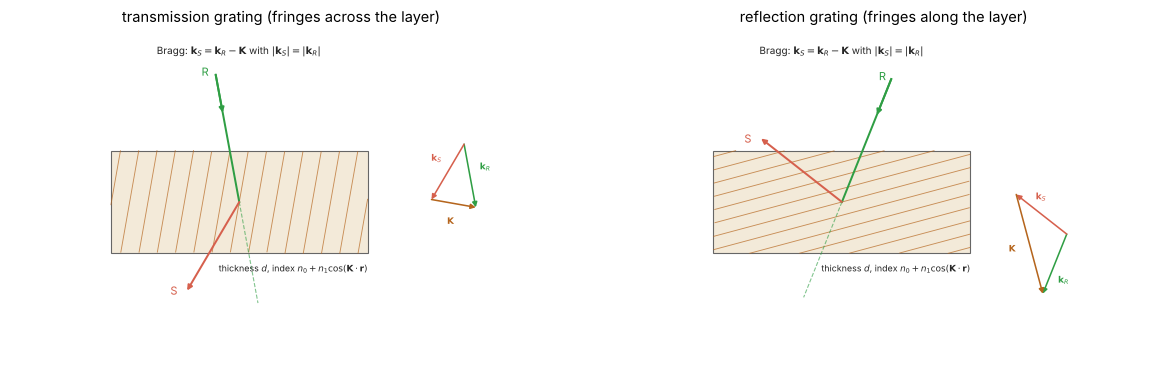

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
sketch.volume_grating_layout(axs[0], "transmission", title="transmission grating (fringes across the layer)")
sketch.volume_grating_layout(axs[1], "reflection", title="reflection grating (fringes along the layer)")
plt.show()

## 2. Transmission gratings

For a lossless transmission grating Kogelnik finds

$$\eta = \frac{\sin^2\sqrt{\nu^2 + \xi^2}}{1 + \xi^2/\nu^2},\qquad
\nu = \frac{\pi n_1 d}{\lambda\sqrt{c_R c_S}},\qquad \xi = \frac{\vartheta d}{2c_S},$$

with $c_R = \cos\theta$ and the thickness $d$. At Bragg ($\xi = 0$)
the power swings between the two waves as $\sin^2\nu$: 100 % at
$\nu = \pi/2$, i.e. $n_1 d = \lambda\sqrt{c_Rc_S}/2$, and back to zero at
$\nu = \pi$ (over-modulation). Off Bragg the efficiency falls, and its
first zero is at $\sqrt{\nu^2 + \xi^2} = \pi$: the angular half width is
about $\Lambda/d$ in the medium, so thick gratings are selective.

A photopolymer of today (e.g. Covestro Bayfol HX) has $n_0 \approx 1.50$
and reaches $n_1$ of 0.01 to 0.03. Below a 1000 lines/mm grating
($\Lambda = 1\,\mu$m) for 532 nm, without slant, at three thicknesses
chosen for 100 % at Bragg, with $n_1$ from $\nu = \pi/2$, computed with
Kogelnik and with RCWA (the medium on both sides index-matched, as
Kogelnik assumes).

Bragg angle in the medium 10.21°, in air 15.43°


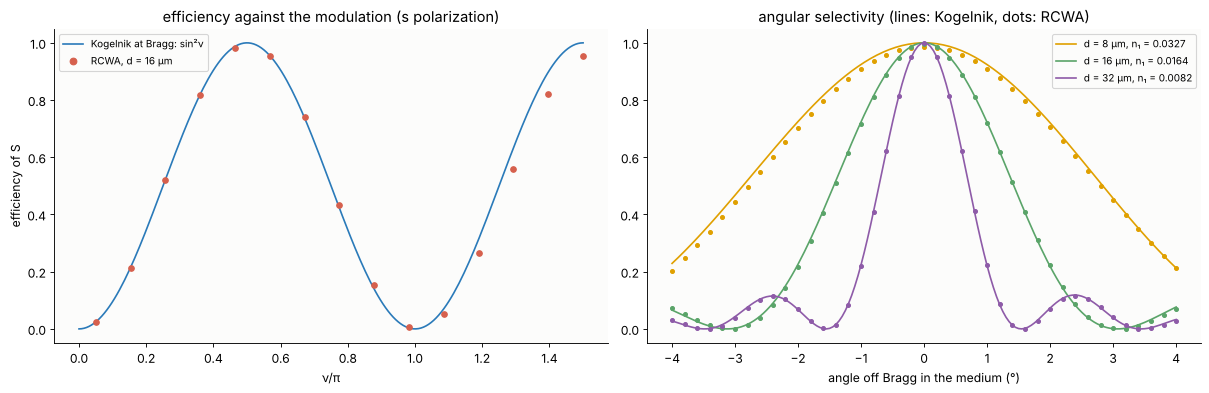

d =    8 µm: FWHM 5.65° in the medium, Λ/d = 7.16°
d =   16 µm: FWHM 2.80° in the medium, Λ/d = 3.58°
d =   32 µm: FWHM 1.40° in the medium, Λ/d = 1.79°


In [3]:
LAM = 0.532                       # µm
N0 = 1.50
LAM_G = 1.0                       # grating period (µm)
th_b = arvr.bragg_angle(LAM_G, LAM, N0, np.pi/2)
print("Bragg angle in the medium {:.2f}°, in air {:.2f}°".format(
    np.degrees(th_b), np.degrees(np.arcsin(N0*np.sin(th_b)))))


def rcwa_vhg(theta, lam, period, d, n1, slant=np.pi/2, pol="s", n_orders=10, n_slices=48):
    """Efficiency of the order -1 (transmitted for c_S > 0, reflected otherwise) with RCWA."""
    K = 2*np.pi/period
    px = period/np.sin(slant)
    layers = arvr.volume_grating(px, d, N0, n1, slant_phase=K*np.cos(slant)*d, n_slices=n_slices)
    r = rcwa(px, layers, lam, k_x=N0*np.sin(np.atleast_1d(theta)), n_in=N0, n_out=N0,
             n_orders=n_orders)
    R, T = r.efficiencies(np.array((0, 1) if pol == "s" else (1, 0), dtype=complex))
    i = np.where(r.m == -1)[0][0]
    return T[:, i], R[:, i], T, r.m


thick = (8.0, 16.0, 32.0)
dth = np.radians(np.linspace(-4, 4, 161))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
nu = np.linspace(0, 3*np.pi/2, 200)
axs[0].plot(nu/np.pi, np.sin(nu)**2, color=BLUE, label="Kogelnik at Bragg: sin²ν")
d0 = 16.0
for nu_k in np.linspace(0.05, 1.5, 15)*np.pi:
    n1 = nu_k*LAM*np.cos(th_b)/(np.pi*d0)
    axs[0].plot(nu_k/np.pi, rcwa_vhg(th_b, LAM, LAM_G, d0, n1)[0][0], "o", color=RED, ms=5)
axs[0].plot([], [], "o", color=RED, label="RCWA, d = 16 µm")
axs[0].set_xlabel("ν/π")
axs[0].set_ylabel("efficiency of S")
axs[0].set_title("efficiency against the modulation (s polarization)")
axs[0].legend(fontsize=9)
widths = {}
for d, c in zip(thick, (ORANGE, GREEN, PURPLE)):
    n1 = LAM*np.cos(th_b)/(2*d)
    eta_k = arvr.kogelnik(th_b + dth, LAM, LAM_G, d, N0, n1)
    eta_r = rcwa_vhg(th_b + dth[::4], LAM, LAM_G, d, n1)[0]
    axs[1].plot(np.degrees(dth), eta_k, color=c, label="d = {:.0f} µm, n₁ = {:.4f}".format(d, n1))
    axs[1].plot(np.degrees(dth[::4]), eta_r, "o", color=c, ms=3.5)
    above = np.degrees(dth[eta_k >= 0.5])
    widths[d] = above.max() - above.min()
axs[1].set_xlabel("angle off Bragg in the medium (°)")
axs[1].set_title("angular selectivity (lines: Kogelnik, dots: RCWA)")
axs[1].legend(fontsize=9)
plt.show()
for d in thick:
    print("d = {:4.0f} µm: FWHM {:.2f}° in the medium, Λ/d = {:.2f}°".format(
        d, widths[d], np.degrees(LAM_G/d)))

With 1000 lines/mm and 532 nm the Bragg angle is 10.2° in the
medium (15.4° in air). At Bragg the RCWA efficiency follows Kogelnik's
$\sin^2\nu$: full conversion at $\nu = \pi/2$, none at $\nu = \pi$,
where the diffracted wave has given its power back. Beyond $\nu = \pi$
RCWA falls a little below Kogelnik (0.95 instead of 1 at $1.5\pi$): with
$n_1 = 0.025$ at 16 µm the other orders start to take a share.

The angular selectivity halves with every doubling of the thickness: the
full width at half maximum is 5.7°, 2.8° and 1.4° in the medium for 8, 16
and 32 µm, about 0.8 $\Lambda/d$. The side lobes are the familiar
$\mathrm{sinc}^2$ of a finite grating. Kogelnik and RCWA agree to about a
per cent; the small asymmetry of the thin grating (RCWA a little lower on
the left) is the coupling to the other orders that the two-wave theory
leaves out.

**When is a grating thick?** Kogelnik keeps only two waves. That is
right when the other orders are far from Bragg, which Klein and Cook
measured by the parameter

$$Q = \frac{2\pi\lambda d}{n_0\Lambda^2}.$$

For $Q \gg 1$ (in practice $Q > 10$) a grating is thick: one order only.
For $Q \lesssim 1$ it is thin (Raman–Nath regime), and many orders appear
with Bessel function efficiencies, like the scalar phase gratings of the
early notebooks. Below, the same grating at the Bragg angle with
$\nu = \pi/2$ but ever thinner (and with ever stronger modulation), with
RCWA keeping all orders.

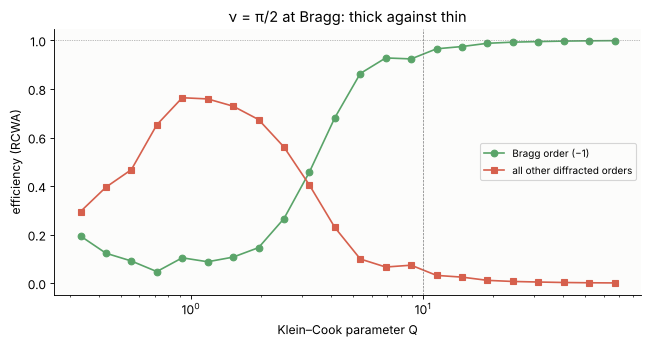

Q =    0.33: Bragg order 0.194
Q =    0.92: Bragg order 0.105
Q =    2.52: Bragg order 0.266
Q =    6.90: Bragg order 0.928
Q =   18.93: Bragg order 0.988
Q =   51.95: Bragg order 0.998


In [4]:
d_q = np.geomspace(0.15, 30, 22)
Q = 2*np.pi*LAM*d_q/(N0*LAM_G**2)
eta_m1, eta_other = [], []
for d in d_q:
    n1 = LAM*np.cos(th_b)/(2*d)
    e, _, T, m = rcwa_vhg(th_b, LAM, LAM_G, d, n1, n_orders=12, n_slices=1)
    eta_m1.append(e[0])
    eta_other.append(T[0].sum() - e[0] - T[0, m == 0][0])
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
ax.semilogx(Q, eta_m1, "o-", color=GREEN, label="Bragg order (−1)")
ax.semilogx(Q, eta_other, "s-", color=RED, label="all other diffracted orders")
ax.axhline(1.0, color=GREY, lw=0.6, ls=":")
ax.axvline(10, color=GREY, lw=0.6, ls="--")
ax.set_xlabel("Klein–Cook parameter Q")
ax.set_ylabel("efficiency (RCWA)")
ax.set_title("ν = π/2 at Bragg: thick against thin")
ax.legend(fontsize=9)
plt.show()
for q, e in zip(Q[::4], eta_m1[::4]):
    print("Q = {:7.2f}: Bragg order {:.3f}".format(q, e))

Above $Q \approx 10$ the Bragg order takes 97 % or more (99.8 % at
$Q = 52$): the grating is thick and Kogelnik's two waves are all there
is. Below $Q \approx 3$ the same $\nu = \pi/2$ sends most of the light
into other orders, and the Bragg order gets only 10 to 25 %: a thin
grating behaves like a phase grating with Bessel function orders. The
1000 lines/mm grating at 532 nm needs about 10 µm to be thick; the
photopolymer layers of holographic combiners (10 to 20 µm) are just in
the thick regime, which is why their selectivity is a matter of degrees
rather than tenths of degrees.

**Slant and polarization.** Waveguide couplers use slanted fringes, so
that the light diffracted from near normal incidence travels steeply in the
plate. For p polarization, the coupling is weaker by
$\cos 2(\theta - \phi)$, the angle between the electric fields of R and S;
for a 90° deflection it vanishes (the Brewster condition of the fringes).
Below, a slanted transmission grating that turns light at normal incidence
by 50° in the medium, for s and p, Kogelnik against RCWA.

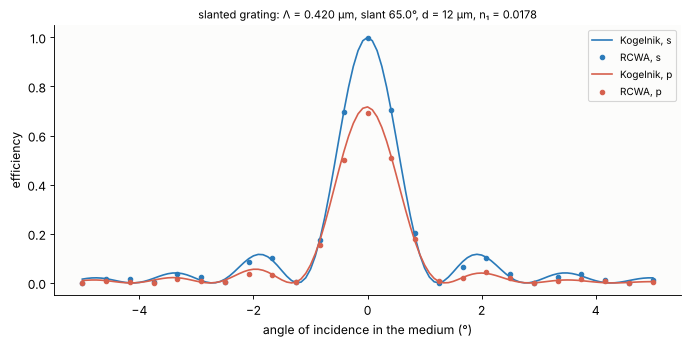

at Bragg: Kogelnik s 1.000, p 0.717; RCWA s 0.998, p 0.692


In [5]:
# fringes that send theta = 0 to -50° in the medium
dev = np.radians(50.0)
K_vec = N0*2*np.pi/LAM*np.array([np.sin(dev), 1 - np.cos(dev)])   # rho - sigma, with rho along z
slant_s = np.arctan2(K_vec[0], K_vec[1])
Lam_s = 2*np.pi/np.hypot(*K_vec)
d_s = 12.0
n1_s = LAM/(2*d_s)*np.sqrt(np.cos(0.0)*np.cos(dev))     # nu = pi/2 for s
dth_s = np.radians(np.linspace(-5, 5, 121))
fig, ax = plt.subplots(figsize=(8.5, 4.2), layout="constrained")
for pol, c in (("s", BLUE), ("p", RED)):
    ax.plot(np.degrees(dth_s), arvr.kogelnik(dth_s, LAM, Lam_s, d_s, N0, n1_s, slant=slant_s, polarization=pol),
            color=c, label="Kogelnik, " + pol)
    ax.plot(np.degrees(dth_s[::5]), rcwa_vhg(dth_s[::5], LAM, Lam_s, d_s, n1_s, slant=slant_s, pol=pol,
                                             n_slices=96)[0], "o", color=c, ms=4, label="RCWA, " + pol)
ax.set_xlabel("angle of incidence in the medium (°)")
ax.set_ylabel("efficiency")
ax.set_title("slanted grating: Λ = {:.3f} µm, slant {:.1f}°, d = {:.0f} µm, n₁ = {:.4f}".format(
    Lam_s, np.degrees(slant_s), d_s, n1_s), fontsize=10)
ax.legend(fontsize=9)
plt.show()
e_s = arvr.kogelnik(0.0, LAM, Lam_s, d_s, N0, n1_s, slant=slant_s, polarization="s")
e_p = arvr.kogelnik(0.0, LAM, Lam_s, d_s, N0, n1_s, slant=slant_s, polarization="p")
print("at Bragg: Kogelnik s {:.3f}, p {:.3f}; RCWA s {:.3f}, p {:.3f}".format(
    float(e_s), float(e_p), rcwa_vhg(0.0, LAM, Lam_s, d_s, n1_s, slant=slant_s, n_slices=96)[0][0],
    rcwa_vhg(0.0, LAM, Lam_s, d_s, n1_s, slant=slant_s, pol="p", n_slices=96)[0][0]))

At Bragg Kogelnik gives 100 % for s and 72 % for p; RCWA gives 99.8 %
and 69 %. The p coupling is weaker by $\cos 2(\theta - \phi) = \cos 50°$,
so with the thickness chosen for s the p wave is under-modulated. A grating
that deflects by 90° in the medium does not diffract p at all, and
combiners that turn light steeply into a plate are polarization
selective for this reason. The angular curves agree in shape, side lobes
included; the 96 slices of the staircase are enough here.

## 3. Reflection gratings

With the fringes parallel to the surface ($\phi = 0$) the hologram is a
Bragg mirror: a stack of weak, smoothly varying layers, the sinusoidal
relative of the quarter-wave stacks of
notebook 14 (coated laser mirror). Kogelnik's
result for a lossless reflection grating is

$$\eta = \left[1 + \frac{1 - \xi^2/\nu^2}{\sinh^2\sqrt{\nu^2 - \xi^2}}\right]^{-1},$$

$\tanh^2\nu$ at Bragg: the efficiency approaches 100 % without
over-modulation, since the reflected wave travels back through the parts
of the grating it already left. Because there is no lateral period, the
grating can be computed exactly as a thin film stack: 2000 slices of
$n(z) = n_0 + n_1\cos(Kz)$ with `thin_films`. Below a grating for 532 nm
at normal incidence ($\Lambda = \lambda/2n_0$), $n_1 = 0.02$, as the
spectrum at three thicknesses.

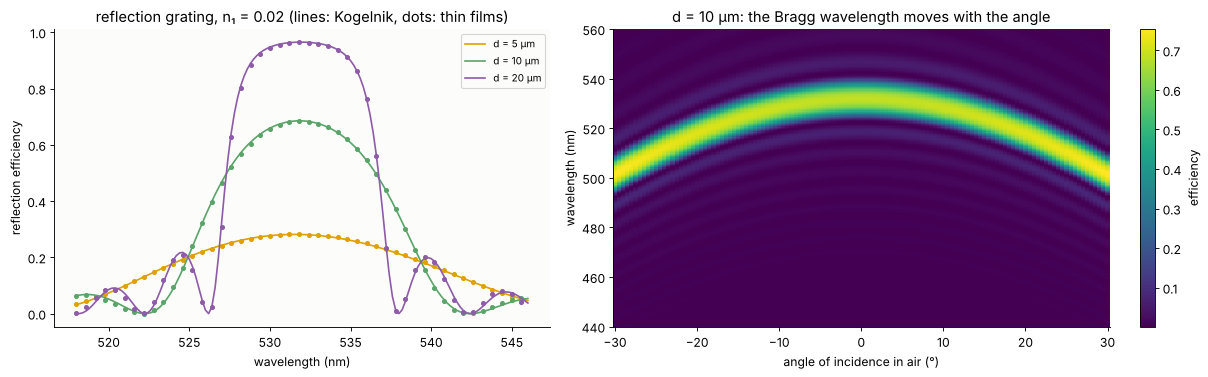

d =    5 µm: peak 0.282, FWHM 18.60 nm
d =   10 µm: peak 0.685, FWHM 12.00 nm
d =   20 µm: peak 0.965, FWHM 9.20 nm
Bragg wavelength at 30° in air: 501.6 nm (2 n0 Λ cos θ_medium)


In [6]:
LAM_NM = 532.0
LAM_R = LAM_NM/(2*N0)                        # nm
N1_R = 0.02
lam_r = np.linspace(518, 546, 141)


def stack_reflectance(d_nm, lam_nm, theta=0.0, n1=N1_R, n_slices=2000, pol="s"):
    z = (np.arange(n_slices) + 0.5)*d_nm/n_slices
    nz = N0 + n1*np.cos(2*np.pi*z/LAM_R)
    return tf.R_T_A_coeffs(theta, nz, np.zeros(n_slices), np.full(n_slices, d_nm/n_slices), N0, 0.0,
                           N0, 0.0, pol, lam_nm)[0]


fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
bw = {}
for d_um, c in ((5.0, ORANGE), (10.0, GREEN), (20.0, PURPLE)):
    k = arvr.kogelnik(0.0, lam_r, LAM_R, d_um*1e3, N0, N1_R, slant=0.0)
    s = np.array([stack_reflectance(d_um*1e3, l) for l in lam_r[::3]])
    axs[0].plot(lam_r, k, color=c, label="d = {:.0f} µm".format(d_um))
    axs[0].plot(lam_r[::3], s, "o", color=c, ms=3.5)
    above = lam_r[k >= 0.5*k.max()]
    bw[d_um] = (k.max(), above.max() - above.min())
axs[0].set_xlabel("wavelength (nm)")
axs[0].set_ylabel("reflection efficiency")
axs[0].set_title("reflection grating, n₁ = 0.02 (lines: Kogelnik, dots: thin films)")
axs[0].legend(fontsize=9)
# angle-wavelength map of the 10 µm grating
th_air = np.radians(np.linspace(-30, 30, 121))
lam_map = np.linspace(440, 560, 241)
TH, LM = np.meshgrid(np.arcsin(np.sin(th_air)/N0), lam_map)
E = arvr.kogelnik(TH, LM, LAM_R, 10e3, N0, N1_R, slant=0.0)
im = axs[1].pcolormesh(np.degrees(th_air), lam_map, E, cmap="viridis", shading="auto")
fig.colorbar(im, ax=axs[1], label="efficiency")
axs[1].set_xlabel("angle of incidence in air (°)")
axs[1].set_ylabel("wavelength (nm)")
axs[1].set_title("d = 10 µm: the Bragg wavelength moves with the angle")
plt.show()
for d_um, (pk, w) in bw.items():
    print("d = {:4.0f} µm: peak {:.3f}, FWHM {:.2f} nm".format(d_um, pk, w))
print("Bragg wavelength at 30° in air: {:.1f} nm (2 n0 Λ cos θ_medium)".format(
    2*N0*LAM_R*np.cos(np.arcsin(0.5/N0))))

The thin film transfer matrices, which are exact for a layered
medium, and Kogelnik agree on every point: 28 %, 69 % and 97 % at Bragg
for 5, 10 and 20 µm, i.e. $\tanh^2(\pi n_1 d/\lambda)$. Unlike the
transmission grating, more thickness never hurts the peak, and the band
narrows to a limit: 18.6, 12.0 and 9.2 nm. The limit is the photonic band
gap of the sinusoidal mirror, $\Delta\lambda = \lambda n_1/n_0
= 7.1$ nm, the range in which the coupled waves cannot propagate; the
20 µm grating, with 9.2 nm at half maximum, is close to it, and thinner
gratings are broader because they are too short to build it up.

The map shows the coupling between angle and colour: tilted by 30° in
air, the grating reflects 502 nm instead of 532 nm, the
$2n_0\Lambda\cos\theta$ of the Bragg condition. A reflection
hologram lit by white light reflects one colour per direction, the
"rainbow" of the security holograms on bank notes in reverse: here each
angle gets its own narrow colour. For a combiner this means that a
reflection VHG works only with narrow band light (lasers or filtered
LEDs), and that each field angle of the image needs the right wavelength.

## 4. Selectivity as a design parameter

**Field of view of a VHG in-coupler.** Take a photopolymer layer
($n_0 = 1.50$, 15 µm, $n_1 = 0.02$) on a glass plate of the same index
that couples green light from near normal incidence into the plate at
55° (past the critical angle of 41.8°). A slanted reflection grating does
this: the light enters the layer, is reflected by the fringes and
travels back into the plate at 55° from the normal, now on the other side.
The angular acceptance of the grating, a few degrees in air, is the field
of view it can couple. Recording several gratings with different slants in
the same layer (**multiplexing**) widens the field, but they share the
index modulation: with $M$ gratings each gets about $n_1/M$, and since
$\eta \approx \nu^2 \propto n_1^2$ for weak gratings, the total efficiency
of a field drops roughly as $1/M$. Below, one grating and five
multiplexed ones, Kogelnik for each and the fields summed (cross-talk
between the gratings ignored).

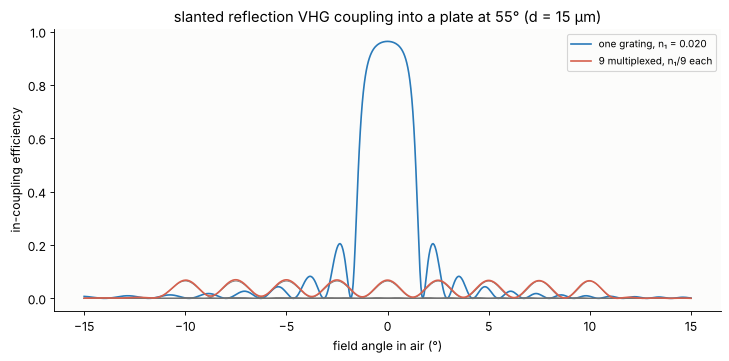

one grating: Λ = 0.200 µm, slant -27.5°, peak 0.96, FWHM 2.8° in air
multiplexed: mean efficiency over ±12° 0.03, min 0.00


In [7]:
th_guide = np.radians(55.0)          # in the plate, from the normal
d_in, n1_in = 15.0, 0.02


def coupler_grating(theta_in_medium):
    """Reflection grating that sends theta_in_medium (towards +z) to -th_guide... back at th_guide."""
    beta = 2*np.pi*N0/LAM
    rho = beta*np.array([np.sin(theta_in_medium), np.cos(theta_in_medium)])
    sigma = beta*np.array([np.sin(th_guide), -np.cos(th_guide)])
    Kv = rho - sigma
    return 2*np.pi/np.hypot(*Kv), np.arctan2(Kv[0], Kv[1])


th_field_air = np.radians(np.linspace(-15, 15, 601))
th_field = np.arcsin(np.sin(th_field_air)/N0)
fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
L1, s1 = coupler_grating(0.0)
e1 = arvr.kogelnik(th_field, LAM, L1, d_in, N0, n1_in, slant=s1)
ax.plot(np.degrees(th_field_air), e1, color=BLUE, label="one grating, n₁ = {:.3f}".format(n1_in))
M = 9
centres = np.radians(np.linspace(-10, 10, M))
etot = np.zeros_like(th_field)
for c in centres:
    Lm, sm = coupler_grating(np.arcsin(np.sin(c)/N0))
    em = arvr.kogelnik(th_field, LAM, Lm, d_in, N0, n1_in/M, slant=sm)
    ax.plot(np.degrees(th_field_air), em, color=GREY, lw=0.7)
    etot += em
ax.plot(np.degrees(th_field_air), etot, color=RED, label="{} multiplexed, n₁/{} each".format(M, M))
ax.set_xlabel("field angle in air (°)")
ax.set_ylabel("in-coupling efficiency")
ax.set_title("slanted reflection VHG coupling into a plate at 55° (d = 15 µm)")
ax.legend(fontsize=9)
plt.show()
above = np.degrees(th_field_air[e1 >= 0.5*e1.max()])
print("one grating: Λ = {:.3f} µm, slant {:.1f}°, peak {:.2f}, FWHM {:.1f}° in air".format(
    L1, np.degrees(s1), e1.max(), above.max() - above.min()))
print("multiplexed: mean efficiency over ±12° {:.2f}, min {:.2f}".format(
    etot[np.abs(th_field_air) < np.radians(12)].mean(), etot[np.abs(th_field_air) < np.radians(12)].min()))

A single grating (period 0.200 µm, fringes slanted by −27.5°) couples
96 % at its Bragg angle, but only over 2.8° (FWHM) in air. Nine
multiplexed gratings, each with a ninth of the index modulation, cover
±12° with peaks of only a few per cent each and dips between them: the
weak gratings are in the linear regime, where the efficiency goes with
$n_1^2$, so splitting the modulation over $M$ gratings divides the
efficiency of each field by about $M$. This is the basic trade of VHG
combiners: either a small field of view at high efficiency, or a large
one at low efficiency, unless the index modulation of the material grows.
Photopolymer development has been chasing larger $n_1$ for exactly this
reason; thinner layers widen the acceptance but lower $\nu$ again.

**No rainbow.** The rainbow of
notebook 123 (AR waveguide combiners, section 5)
comes from world light that the out-coupler diffracts into the eye. A
surface relief grating does that for any angle that the grating equation
allows; a volume grating only near Bragg. Below, the efficiency with
which the out-coupler version of the grating above (the same grating,
reached from the world side) diffracts white light from all directions of
the world, against the wavelength and the angle: a narrow streak, and
only for light at the right angle and colour. Most of the sky passes the
hologram untouched, which is the main selling point of holographic
combiners against their smaller field of view.

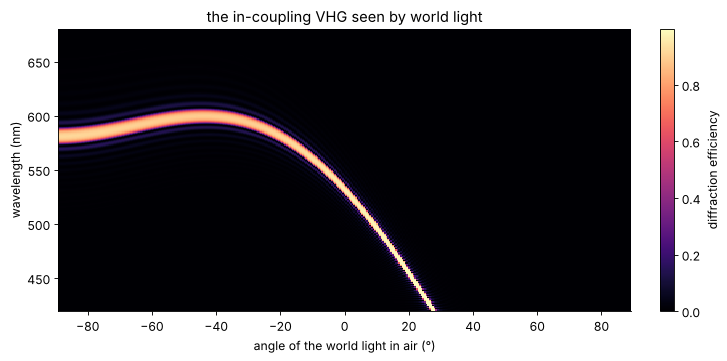

fraction of (angle, wavelength) cells with efficiency > 1 %: 12.61%
efficiency for white light averaged over all angles: 2.913%


In [8]:
lam_w = np.linspace(0.42, 0.68, 261)
th_w_air = np.radians(np.linspace(-89, 89, 357))
TW, LW = np.meshgrid(np.arcsin(np.sin(th_w_air)/N0), lam_w)
EW = arvr.kogelnik(TW, LW, L1, d_in, N0, n1_in, slant=s1)
fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
im = ax.pcolormesh(np.degrees(th_w_air), lam_w*1e3, EW, cmap="magma", shading="auto")
fig.colorbar(im, ax=ax, label="diffraction efficiency")
ax.set_xlabel("angle of the world light in air (°)")
ax.set_ylabel("wavelength (nm)")
ax.set_title("the in-coupling VHG seen by world light")
plt.show()
print("fraction of (angle, wavelength) cells with efficiency > 1 %: {:.2%}".format((EW > 0.01).mean()))
print("efficiency for white light averaged over all angles: {:.3%}".format(EW.mean()))

The light of the world that the grating diffracts lies on one thin
curve in the plane of angle and wavelength: for each direction, a band of
about 10 nm. Averaged over all directions and the visible, the grating
diffracts 2.9 % of white light, and only 12.6 % of the (angle,
wavelength) cells reach even 1 %. The diffracted light goes into the
plate at the guided angle, not into the eye, so it is a loss, not an
image; the world seen through the grating is very slightly tinted in the
complementary colour at the angles of the curve. The surface relief
out-coupler of
notebook 123 (AR waveguide combiners) instead
diffracts every colour that the grating equation allows, with a smooth
efficiency, into directions that can reach the eye.

## Summary

- A volume grating diffracts strongly only at the Bragg angle and
  wavelength. Kogelnik's two-wave theory gives the efficiency in closed
  form: $\sin^2$ for transmission gratings, $\tanh^2$ for reflection
  gratings at Bragg, and it agrees with RCWA and with thin film matrices to
  about a per cent for thick gratings.
- Thickness buys selectivity: the angular width is about $\Lambda/d$ and
  the spectral width of a reflection grating about $\lambda\Lambda/d$.
  The Klein–Cook parameter $Q$ says when the two-wave picture holds.
- For combiners, selectivity is both the problem (a few degrees of field
  per grating, multiplexing that dilutes the index modulation) and the
  solution (no rainbow, a nearly transparent window to the world).

## References

- H. Kogelnik, "Coupled wave theory for thick hologram gratings", Bell
  Syst. Tech. J. 48, 2909–2947 (1969).
- W. R. Klein and B. D. Cook, "Unified approach to ultrasonic light
  diffraction", IEEE Trans. Sonics Ultrason. 14, 123–134 (1967).
- M. G. Moharam and T. K. Gaylord, "Rigorous coupled-wave analysis of
  planar-grating diffraction", J. Opt. Soc. Am. 71, 811–818 (1981).
- F.-K. Bruder, T. Fäcke and T. Rölle, "The chemistry and physics of
  Bayfol® HX film holographic photopolymer", Polymers 9, 472 (2017).
- B. C. Kress, *Optical Architectures for Augmented-, Virtual-, and
  Mixed-Reality Headsets*, SPIE Press (2020).

In [9]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 17 s
